# Unit 4 Seminar – Correlation and Regression
Population vs. GDP per capita (2001–2021)

## Step 1: Importing the required packages

In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn import linear_model
from sklearn.metrics import r2_score

**Result:** All packages loaded without errors.

## Step 2: Load the data

In [147]:
gdp = pd.read_csv("Unit_4_Global_GDP.csv", encoding="utf-8-sig")
pop = pd.read_csv("Unit_4_Global_Population.csv", encoding="utf-8-sig")

print("GDP:", gdp.shape)
print("Population:", pop.shape)

GDP: (266, 65)
Population: (272, 66)


In [148]:
print("GDP – last 3 columns:", list(gdp.columns[-3:]))
print("Population – last 3 columns:", list(pop.columns[-3:]))

GDP – last 3 columns: ['2018', '2019', '2020']
Population – last 3 columns: ['2019', '2020', '2021']


**Result:** The GDP dataset has 266 rows and 65 columns, the population dataset 272 rows and 66 columns. The population data goes up to 2021, the GDP data only up to 2020. The row counts differ, so the two files don't contain exactly the same entries.

## Step 3: First look at the data

In [149]:
gdp.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,2.549721e+09,2.534637e+09,2.727850e+09,2.790849e+09,2.962905e+09,2.983637e+09,3.092430e+09,3.202189e+09,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP (current US$),NY.GDP.MKTP.CD,1.929944e+10,1.970954e+10,2.147872e+10,2.571501e+10,2.351080e+10,2.679160e+10,...,9.427110e+11,9.498490e+11,9.635600e+11,9.837490e+11,9.186470e+11,8.720230e+11,9.842560e+11,1.011720e+12,1.008380e+12,9.188150e+11
2,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,5.377778e+08,5.488889e+08,5.466667e+08,7.511112e+08,8.000000e+08,1.006667e+09,...,1.780511e+10,1.990732e+10,2.014640e+10,2.049713e+10,1.913421e+10,1.811656e+10,1.875347e+10,1.805323e+10,1.879945e+10,2.011614e+10
3,Africa Western and Central,AFW,GDP (current US$),NY.GDP.MKTP.CD,1.040428e+10,1.112805e+10,1.194335e+10,1.267652e+10,1.383858e+10,1.486247e+10,...,6.709630e+11,7.275710e+11,8.207880e+11,8.514870e+11,7.607300e+11,6.905430e+11,6.837420e+11,7.416920e+11,7.945720e+11,7.845880e+11
4,Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.117900e+11,1.280530e+11,1.367100e+11,1.457120e+11,1.161940e+11,1.011240e+11,1.221240e+11,1.013530e+11,8.941719e+10,5.837598e+10


**Result (GDP):** The indicator is "GDP (current US\$)", i.e. the total GDP of each country, not GDP per capita. GDP per capita has to be calculated as GDP ÷ population. The table also contains regions (e.g. "Africa Eastern and Southern"), not only countries, and these have to be removed. There are missing values (NaN), including within 2001–2020 (e.g. Aruba 2019 and 2020).

In [150]:
pop.head()

,Country Name,Country Code,Series Name,Series Code,1960,1961,1962,1963,1964,1965,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54211,55438,56225,56695,57032,57360,...,102560,103159,103774,104341,104872,105366,105845,106314,NaN,NaN
1,Afghanistan,AFG,"Population, total",SP.POP.TOTL,8996967,9169406,9351442,9543200,9744772,9956318,...,31161378,32269592,33370804,34413603,35383028,36296111,37171922,38041757,38928341,39835000
2,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130836765,134159786,137614644,141202036,144920186,148769974,...,547482863,562601578,578075373,593871847,609978946,626392880,643090131,660046272,677243299,694664000
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,96396419,98407221,100506960,102691339,104953470,107289875,...,370243017,380437896,390882979,401586651,412551299,423769930,435229381,446911598,458803476,470898000
4,Albania,ALB,"Population, total",SP.POP.TOTL,1608800,1659800,1711319,1762621,1814135,1864791,...,2900401,2895092,2889104,2880703,2876101,2873457,2866376,2854191,2837743,2832000


**Result (Population):** The indicator is "Population, total". This table also contains regions, not only countries, and has missing values (e.g. Aruba 2020 and 2021). The rows are in a different order than in the GDP table, so the two tables have to be matched by Country Code, not by row position. The 2021 values appear rounded (ending in 000), so they're probably estimates.

## Step 4: Check the end of the tables

In [151]:
gdp.tail()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
261,Kosovo,XKX,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,6.341737e+09,6.163785e+09,6.735731e+09,7.074658e+09,6.295820e+09,6.682833e+09,7.180813e+09,7.878509e+09,7.899879e+09,7.716925e+09
262,"Yemen, Rep.",YEM,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.272642e+10,3.540134e+10,4.041524e+10,4.322859e+10,4.244510e+10,3.131737e+10,2.684013e+10,2.160614e+10,NaN,NaN
263,South Africa,ZAF,GDP (current US$),NY.GDP.MKTP.CD,7.575397e+09,7.972997e+09,8.497997e+09,9.423396e+09,1.037400e+10,1.133440e+10,...,4.582020e+11,4.344010e+11,4.008860e+11,3.811990e+11,3.467100e+11,3.235860e+11,3.814490e+11,4.048420e+11,3.879350e+11,3.354420e+11
264,Zambia,ZMB,GDP (current US$),NY.GDP.MKTP.CD,7.130000e+08,6.962857e+08,6.931429e+08,7.187143e+08,8.394286e+08,1.082857e+09,...,2.345952e+10,2.550306e+10,2.803724e+10,2.714102e+10,2.125122e+10,2.095841e+10,2.587360e+10,2.631159e+10,2.330867e+10,1.811063e+10
265,Zimbabwe,ZWE,GDP (current US$),NY.GDP.MKTP.CD,1.052990e+09,1.096647e+09,1.117602e+09,1.159512e+09,1.217138e+09,1.311436e+09,...,1.410192e+10,1.711485e+10,1.909102e+10,1.949552e+10,1.996312e+10,2.054868e+10,1.758489e+10,1.811554e+10,1.928429e+10,1.805117e+10


**Result (GDP):** The table ends with real countries, there are no notes or extra rows at the end. The year columns contain only numbers and NaN. More missing values within our period: e.g. Yemen 2019 and 2020.

In [152]:
pop.tail(8)

,Country Name,Country Code,Series Name,Series Code,1960,1961,1962,1963,1964,1965,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
264,"Yemen, Rep.",YEM,"Population, total",SP.POP.TOTL,5315351,5393034,5473671,5556767,5641598,5727745,...,24473176,25147112,25823488,26497881,27168210,27834811,28498683,29161922,29825968,30491000
265,Zambia,ZMB,"Population, total",SP.POP.TOTL,3070780,3164330,3260645,3360099,3463211,3570466,...,14465148,14926551,15399793,15879370,16363449,16853608,17351714,17861034,18383956,18921000
266,Zimbabwe,ZWE,"Population, total",SP.POP.TOTL,3776679,3905038,4039209,4178726,4322854,4471178,...,13115149,13350378,13586710,13814642,14030338,14236599,14438812,14645473,14862927,15092000
267,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
268,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
269,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
270,Data from database: Population estimates and p...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
271,Last Updated: 12/17/2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Result (Population):** The last 5 rows are not countries: 3 empty rows and 2 notes from the World Bank ("Data from database…", "Last Updated: 12/17/2021"). These rows have no Country Code and need to be removed. The note confirms that the data was updated in December 2021, so the 2021 values are estimates. Without these 5 rows, the population table has 267 entries, one more than the GDP table.

## Step 5: Check the data types

In [153]:
print("GDP:")
print(gdp.dtypes.value_counts())
print()
print("Population:")
print(pop.dtypes.value_counts())

GDP:
float64    61
object      4
Name: count, dtype: int64

Population:
object    66
Name: count, dtype: int64


**Result:** In the GDP table, all 61 year columns are numbers (float64), only the 4 descriptive columns are text. In the population table, all 66 columns are text (object), including the year columns. So the year columns must contain values that are not numbers. These have to be found and dealt with before we can calculate means.

## Step 6: Find non-numeric values in the population table

In [154]:
years = [str(y) for y in range(1960, 2022)]

all_values = pd.Series(pop[years].values.ravel())
all_values = all_values.dropna()

not_numbers = all_values[pd.to_numeric(all_values, errors="coerce").isna()]
print(not_numbers.value_counts())

..    357
Name: count, dtype: int64


In [155]:
print(list(not_numbers.unique()))

['..']


**Result:** The population year columns contain the value ".." in 357 cells. This is how the World Bank marks missing data. Pandas reads ".." as text, which is why the year columns were read as text instead of numbers. These values need to be converted to NaN so the columns can be used for calculations.

## Step 7: Convert the population year columns to numbers

In [156]:
pop[years] = pop[years].apply(pd.to_numeric, errors="coerce")

print(pop.dtypes.value_counts())

float64    62
object      4
Name: count, dtype: int64


**Result:** After the conversion, all 62 year columns in the population table are numbers (float64), and only the 4 descriptive columns remain text. The ".." values are now NaN, so both tables can be used for calculations.

## Step 8: Remove empty rows and notes

In [157]:
print("Before – GDP:", gdp.shape, " Population:", pop.shape)

gdp = gdp.dropna(subset=["Country Code"])
pop = pop.dropna(subset=["Country Code"])

print("After  – GDP:", gdp.shape, " Population:", pop.shape)

Before – GDP: (266, 65)  Population: (272, 66)
After  – GDP: (266, 65)  Population: (267, 66)


**Result:** Rows without a Country Code were removed. The GDP table is unchanged (266 rows), so it contained no such rows. The population table went from 272 to 267 rows, which matches the 3 empty rows and 2 notes found in step 4. The population table still has one entry more than the GDP table.

## Step 9: Check which entries are not countries

In [158]:
for name in pop["Country Name"]:
    print(name)

Aruba
Afghanistan
Africa Eastern and Southern
Africa Western and Central
Albania
Algeria
American Samoa
Andorra
Angola
Antigua and Barbuda
Arab World
Argentina
Armenia
Aruba
Australia
Austria
Azerbaijan
Bahamas, The
Bahrain
Bangladesh
Barbados
Belarus
Belgium
Belize
Benin
Bermuda
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
British Virgin Islands
Brunei Darussalam
Bulgaria
Burkina Faso
Burundi
Cabo Verde
Cambodia
Cameroon
Canada
Caribbean small states
Cayman Islands
Central African Republic
Central Europe and the Baltics
Chad
Channel Islands
Chile
China
Colombia
Comoros
Congo, Dem. Rep.
Congo, Rep.
Costa Rica
Cote d'Ivoire
Croatia
Cuba
Curacao
Cyprus
Czech Republic
Denmark
Djibouti
Dominica
Dominican Republic
Early-demographic dividend
East Asia & Pacific
East Asia & Pacific (excluding high income)
East Asia & Pacific (IDA & IBRD countries)
Ecuador
Egypt, Arab Rep.
El Salvador
Equatorial Guinea
Eritrea
Estonia
Eswatini
Ethiopia
Euro area
Europe & Central Asia
Europe & Central 

**Result:** The list contains many entries that are not single countries but groups: geographic regions, income groups, World Bank lending groups, demographic groups, political groups (e.g. EU, OECD) and "World". These count countries more than once and need to be removed.

## Step 10: Check for duplicate entries

In [159]:
print("Duplicate country codes – GDP:", gdp["Country Code"].duplicated().sum())
print("Duplicate country codes – Population:", pop["Country Code"].duplicated().sum())

pop[pop["Country Code"].duplicated(keep=False)]

Duplicate country codes – GDP: 0
Duplicate country codes – Population: 1


,Country Name,Country Code,Series Name,Series Code,1960,1961,1962,1963,1964,1965,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54211.0,55438.0,56225.0,56695.0,57032.0,57360.0,...,102560.0,103159.0,103774.0,104341.0,104872.0,105366.0,105845.0,106314.0,NaN,NaN
13,Aruba,ABW,"Population, total",SP.POP.TOTL,54208.0,55434.0,56234.0,56699.0,57029.0,57357.0,...,102565.0,103165.0,103776.0,104339.0,104865.0,105361.0,105846.0,106310.0,106766.0,107000.0


In [160]:
aruba = pop[pop["Country Code"] == "ABW"]
print(aruba.iloc[0].equals(aruba.iloc[1]))

False


In [161]:
row1 = aruba.iloc[0]
row2 = aruba.iloc[1]

same = (row1 == row2) | (row1.isna() & row2.isna())
aruba.loc[:, ~same]

,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,54211.0,55438.0,56225.0,56695.0,57032.0,57360.0,57715.0,58055.0,58386.0,58726.0,...,102560.0,103159.0,103774.0,104341.0,104872.0,105366.0,105845.0,106314.0,NaN,NaN
13,54208.0,55434.0,56234.0,56699.0,57029.0,57357.0,57702.0,58044.0,58377.0,58734.0,...,102565.0,103165.0,103776.0,104339.0,104865.0,105361.0,105846.0,106310.0,106766.0,107000.0


**Result:** The duplicate check finds no duplicates in the GDP table and exactly one in the population table: Aruba appears twice (rows 0 and 13). The rows are not identical: the values differ slightly in most years (by only a few people, under 0.01%), and row 0 has no values for 2020 and 2021. Row 13 is complete and sits in the correct alphabetical position, so row 13 is kept and row 0 is removed.

## Step 11: Remove the duplicate Aruba row

In [162]:
pop = pop.drop(index=0)

print("Population:", pop.shape)
print("Duplicate country codes – Population:", pop["Country Code"].duplicated().sum())

Population: (266, 66)
Duplicate country codes – Population: 0


**Result:** After removing the incomplete Aruba row, the population table has 266 rows, the same number as the GDP table, and no duplicate country codes remain.

## Step 12: Remove regions and other country groups

In [163]:
groups = [
    "Africa Eastern and Southern", "Africa Western and Central", "Arab World",
    "Caribbean small states", "Central Europe and the Baltics",
    "Early-demographic dividend", "East Asia & Pacific",
    "East Asia & Pacific (excluding high income)",
    "East Asia & Pacific (IDA & IBRD countries)", "Euro area",
    "Europe & Central Asia", "Europe & Central Asia (excluding high income)",
    "Europe & Central Asia (IDA & IBRD countries)", "European Union",
    "Fragile and conflict affected situations",
    "Heavily indebted poor countries (HIPC)", "High income", "IBRD only",
    "IDA & IBRD total", "IDA blend", "IDA only", "IDA total",
    "Late-demographic dividend", "Latin America & Caribbean",
    "Latin America & Caribbean (excluding high income)",
    "Latin America & the Caribbean (IDA & IBRD countries)",
    "Least developed countries: UN classification", "Low & middle income",
    "Low income", "Lower middle income", "Middle East & North Africa",
    "Middle East & North Africa (excluding high income)",
    "Middle East & North Africa (IDA & IBRD countries)", "Middle income",
    "North America", "Not classified", "OECD members", "Other small states",
    "Pacific island small states", "Post-demographic dividend",
    "Pre-demographic dividend", "Small states", "South Asia",
    "South Asia (IDA & IBRD)", "Sub-Saharan Africa",
    "Sub-Saharan Africa (excluding high income)",
    "Sub-Saharan Africa (IDA & IBRD countries)", "Upper middle income", "World"
]

print("Names in the list:", len(groups))
print("Found in GDP:", gdp["Country Name"].isin(groups).sum())
print("Found in Population:", pop["Country Name"].isin(groups).sum())

gdp = gdp[~gdp["Country Name"].isin(groups)]
pop = pop[~pop["Country Name"].isin(groups)]

print("After – GDP:", gdp.shape, " Population:", pop.shape)

Names in the list: 49
Found in GDP: 49
Found in Population: 49
After – GDP: (217, 65)  Population: (217, 66)


**Result:** 49 group entries (regions, income groups, lending groups, demographic groups, political groups and "World") were found and removed from both tables. Both tables now have 217 rows, each representing a single country or territory.

## Step 13: Compare the countries in both tables

In [164]:
codes_gdp = set(gdp["Country Code"])
codes_pop = set(pop["Country Code"])

print("Only in GDP:", codes_gdp - codes_pop)
print("Only in Population:", codes_pop - codes_gdp)
print("In both:", len(codes_gdp & codes_pop))

Only in GDP: set()
Only in Population: set()
In both: 217


**Result:** Both tables contain exactly the same 217 country codes. No country is missing from either table, so the two tables can be matched by Country Code.

## Step 14: Missing values from 2001 to 2021

In [165]:
years_pop = [str(y) for y in range(2001, 2022)]
years_gdp = [str(y) for y in range(2001, 2021)]

print("Missing values per year – GDP:")
print(gdp[years_gdp].isna().sum())

Missing values per year – GDP:
2001    17
2002    12
2003    12
2004    12
2005    12
2006    11
2007    11
2008    10
2009    10
2010     9
2011     7
2012     8
2013     7
2014     7
2015     8
2016     9
2017     9
2018     9
2019    12
2020    24
dtype: int64


In [166]:
print("Missing values per year – Population:")
print(pop[years_pop].isna().sum())

Missing values per year – Population:
2001    0
2002    0
2003    0
2004    0
2005    0
2006    0
2007    0
2008    0
2009    0
2010    0
2011    0
2012    1
2013    1
2014    1
2015    1
2016    1
2017    1
2018    1
2019    1
2020    1
2021    5
dtype: int64


**Result:** GDP: between 7 and 24 of the 217 countries are missing a value in each year from 2001 to 2020. Most years have 7–12 missing values (about 3–6%), 2020 has the most (24, about 11%), followed by 2001 (17). Population: no missing values from 2001 to 2011, 1 missing value per year from 2012 to 2020, and 5 in 2021. The gaps are therefore mainly in the GDP data.

## Step 15: Which countries have missing values?

In [167]:
missing_gdp = gdp[years_gdp].isna().sum(axis=1)
missing_gdp.index = gdp["Country Name"]

print("Countries with missing GDP values:", (missing_gdp > 0).sum())
print(missing_gdp[missing_gdp > 0].sort_values(ascending=False))

Countries with missing GDP values: 32
Country Name
St. Martin (French part)     20
Gibraltar                    20
French Polynesia             20
Korea, Dem. People's Rep.    20
British Virgin Islands       20
Channel Islands              13
Somalia                      12
Sint Maarten (Dutch part)    12
South Sudan                  12
Curacao                      10
Eritrea                       9
Nauru                         9
Kosovo                        7
Venezuela, RB                 6
Cayman Islands                5
Aruba                         2
Northern Mariana Islands      2
Virgin Islands (U.S.)         2
Yemen, Rep.                   2
Monaco                        1
Faroe Islands                 1
Greenland                     1
Afghanistan                   1
Andorra                       1
American Samoa                1
Liechtenstein                 1
Isle of Man                   1
Guam                          1
San Marino                    1
New Caledonia        

In [168]:
missing_pop = pop[years_pop].isna().sum(axis=1)
missing_pop.index = pop["Country Name"]

print("Countries with missing population values:", (missing_pop > 0).sum())
print(missing_pop[missing_pop > 0].sort_values(ascending=False))

Countries with missing population values: 5
Country Name
Eritrea                      10
Bermuda                       1
Greenland                     1
Sint Maarten (Dutch part)     1
St. Martin (French part)      1
dtype: int64


**Result:** GDP: 32 of 217 countries have missing values. 5 have no data at all for 2001–2020 (St. Martin, Gibraltar, French Polynesia, North Korea, British Virgin Islands) and cannot be used. 10 have large gaps (5–13 years), partly because they only became independent during the period (e.g. South Sudan 2011, Kosovo 2008). 17 are missing only 1–2 years. The gaps are not random: they mainly affect small territories and countries in conflict or crisis.
Population: only 5 countries have missing values. Eritrea is missing 10 years (2012–2021), the other 4 (Bermuda, Greenland, Sint Maarten, St. Martin) one year each, which matches the 5 missing values in 2021. Eritrea has large gaps in both tables.

## Step 16: Decision on missing values

**Approach:** The mean is calculated from the available years (missing years are skipped). A country is only included if it has GDP per capita for at least 10 of the 20 years (2001–2020).

**Reasoning:**
- Most countries with gaps are missing only 1–2 years (step 15), so a mean over 18–19 years is barely affected.
- Dropping every country with a gap would remove 32 countries, mainly small territories and countries in conflict or crisis. This would bias the sample.
- Filling gaps with the overall average would give very different countries (e.g. Somalia) the same value and distort the data.
- The minimum of 10 years excludes countries with no data or very little data, so that no mean rests on only a few years.

**Note:** GDP per capita requires both GDP and population for the same year. The 10-year rule is therefore applied to GDP per capita, not to the two tables separately.

## Step 17: Calculate GDP per capita (2001–2020)

In [169]:
gdp_years = gdp.set_index("Country Code")[years_gdp]
pop_years = pop.set_index("Country Code")[years_gdp]

gdp_pc = gdp_years / pop_years

print(gdp_pc.shape)
gdp_pc.head()

(217, 20)


,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
Country Code,,,,,,,,,,,,,,,,,,,,
ABW,20670.367007,20436.887127,20833.976354,22568.374990,23300.738363,24046.226381,25834.111780,27083.634863,24631.182057,23513.527694,24985.013915,24712.493268,26441.619939,26893.011506,28396.908424,28452.170619,29350.805023,30253.279359,NaN,NaN
AFG,NaN,179.426579,190.683814,211.382074,242.031313,263.733602,359.693158,364.663542,437.268740,543.306526,591.190030,638.845852,624.315454,614.223342,556.007221,512.012778,516.679862,485.668419,494.179350,516.747871
AGO,527.333529,872.494442,982.961008,1255.564513,1902.422150,2599.565948,3121.996085,4080.941034,3122.781599,3587.883645,4615.481164,5100.102856,5254.886399,5408.404265,4166.992417,3506.078291,4095.816015,3289.636504,2809.626088,1776.166868
ALB,1281.659826,1425.124219,1846.120121,2373.581292,2673.786584,2972.742924,3595.038057,4370.539925,4114.134899,4094.348386,4437.142612,4247.630047,4413.062005,4578.633208,3952.802538,4124.055390,4531.019374,5287.663695,5395.659532,5246.292306
AND,22970.512206,25067.240064,32272.845887,37966.187252,40064.224924,42674.758973,47804.849931,48719.658765,43504.215650,40850.248147,43334.811410,38686.461269,39540.724811,41303.929368,35770.776711,37475.635060,38964.904477,41791.969834,40897.330879,NaN


**Result:** GDP per capita was calculated as GDP ÷ population for each country and year from 2001 to 2020. The new table has 217 rows (countries) and 20 columns (years). The values look plausible (e.g. Afghanistan around 200–600 USD, Andorra around 23,000–48,000 USD). Where GDP or population is missing, GDP per capita is also missing (e.g. Aruba 2019–2020).

## Step 18: Mean population and mean GDP per capita per country

In [170]:
pop_all_years = pop.set_index("Country Code")[years_pop]

df = pd.DataFrame({
    "Country": pop.set_index("Country Code")["Country Name"],
    "MeanPopulation": pop_all_years.mean(axis=1),
    "MeanGDPperCapita": gdp_pc.mean(axis=1),
    "YearsGDPpc": gdp_pc.notna().sum(axis=1)
})

print(df.shape)
print()
print(df.isna().sum())
df.head()

(217, 4)

Country             0
MeanPopulation      0
MeanGDPperCapita    5
YearsGDPpc          0
dtype: int64


,Country,MeanPopulation,MeanGDPperCapita,YearsGDPpc
Country Code,,,,
ABW,Aruba,1.020119e+05,25133.573815,18
AFG,Afghanistan,3.067118e+07,439.055765,19
AGO,Angola,2.465071e+07,3103.856741,20
ALB,Albania,2.930953e+06,3748.051847,20
AND,Andorra,7.852414e+04,38929.541348,19


**Result:** A new table was created with one row per country (217) and four columns: country name, mean population (2001–2021), mean GDP per capita (2001–2020) and the number of years with GDP per capita data. Missing years were skipped when calculating the means. 5 countries have no mean GDP per capita because they have no GDP data at all (see step 15). Example: Aruba has a mean population of about 102,000 and a mean GDP per capita of about 25,100 USD, based on 18 years.

## Step 19: Keep only countries with at least 10 years of GDP per capita data

In [171]:
removed = df[df["YearsGDPpc"] < 10]
print("Removed countries:", len(removed))
print(removed[["Country", "YearsGDPpc"]])
print()

df = df[df["YearsGDPpc"] >= 10]
print("Remaining countries:", len(df))
print(df.isna().sum())

Removed countries: 9
                                Country  YearsGDPpc
Country Code                                       
CHI                     Channel Islands           7
GIB                           Gibraltar           0
MAF            St. Martin (French part)           0
PRK           Korea, Dem. People's Rep.           0
PYF                    French Polynesia           0
SOM                             Somalia           8
SSD                         South Sudan           8
SXM           Sint Maarten (Dutch part)           8
VGB              British Virgin Islands           0

Remaining countries: 208
Country             0
MeanPopulation      0
MeanGDPperCapita    0
YearsGDPpc          0
dtype: int64


**Result:** The 10-year rule removed 9 countries: 5 without any GDP data (Gibraltar, St. Martin, North Korea, French Polynesia, British Virgin Islands) and 4 with only 7–8 years (Channel Islands, Somalia, South Sudan, Sint Maarten). 208 countries remain, with no missing values. Some of the removed countries are among the poorest in the world (Somalia, South Sudan, North Korea), so very poor countries are slightly underrepresented in the final dataset.

## Task A: Correlation
## Step 20: Scatter plot of mean population vs. mean GDP per capita

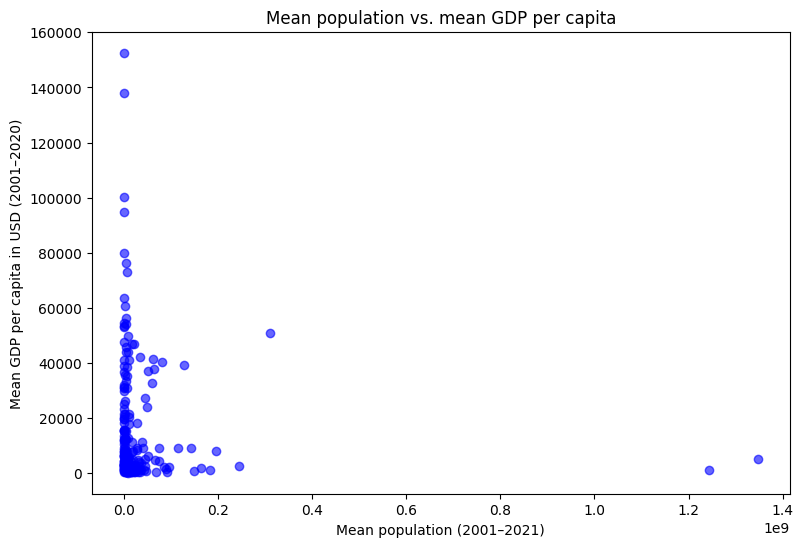

In [172]:
plt.figure(figsize=(9, 6))
plt.scatter(df["MeanPopulation"], df["MeanGDPperCapita"], color="blue", alpha=0.6)
plt.xlabel("Mean population (2001–2021)")
plt.ylabel("Mean GDP per capita in USD (2001–2020)")
plt.title("Mean population vs. mean GDP per capita")
plt.show()

**Result:** The scatter plot shows no visible linear relationship: the points do not rise or fall from left to right. Most countries have a population under about 100 million and range from almost 0 to over 150,000 USD GDP per capita. A few countries lie far from the rest: two with over 1.2 billion people and low GDP per capita, one with about 300 million and high GDP per capita, and a few small countries with very high GDP per capita (95,000–150,000 USD). These extreme values stretch the axes and could strongly influence the correlation.

## Step 21: Identify the countries far from the rest

In [173]:
print("Largest populations:")
print(df.sort_values("MeanPopulation", ascending=False)[["Country", "MeanPopulation", "MeanGDPperCapita"]].head(5))
print()
print("Highest GDP per capita:")
print(df.sort_values("MeanGDPperCapita", ascending=False)[["Country", "MeanPopulation", "MeanGDPperCapita"]].head(5))

Largest populations:
                    Country  MeanPopulation  MeanGDPperCapita
Country Code                                                 
CHN                   China    1.347101e+09       5268.985060
IND                   India    1.243656e+09       1268.737861
USA           United States    3.102702e+08      50754.887317
IDN               Indonesia    2.453600e+08       2660.579776
BRA                  Brazil    1.968927e+08       8088.743745

Highest GDP per capita:
                     Country  MeanPopulation  MeanGDPperCapita
Country Code                                                  
MCO                   Monaco    36092.809524     152610.101196
LIE            Liechtenstein    36200.714286     138115.293315
LUX               Luxembourg   528845.285714     100267.387806
BMU                  Bermuda    64348.950000      94780.323307
CYM           Cayman Islands    56572.857143      79772.726331


**Result:** The countries with the largest populations are China (1.35 billion, about 5,300 USD GDP per capita), India (1.24 billion, about 1,300 USD) and the United States (310 million, about 50,800 USD). The countries with the highest GDP per capita are all very small: Monaco (about 152,600 USD), Liechtenstein (138,100), Luxembourg (100,300) and Bermuda (94,800), each with fewer than 530,000 people. The largest countries differ strongly in GDP per capita, and the richest countries are all small.

## Step 22: Pearson correlation coefficient

In [174]:
r, p_value = stats.pearsonr(df["MeanPopulation"], df["MeanGDPperCapita"])

print("Pearson r:", round(r, 4))
print("p-value:  ", round(p_value, 4))
print("n:        ", len(df))

Pearson r: -0.067
p-value:   0.3362
n:         208


**Result:** Pearson r = −0.067 (p = 0.336, n = 208). The coefficient is very close to 0, so there is practically no linear relationship between mean population and mean GDP per capita. The p-value is well above 0.05, so the result is not statistically significant. This matches the scatter plot. Limitation: Pearson only measures linear relationships and is sensitive to extreme values, and the data contains several strong outliers (e.g. China, India, Monaco).

## Task B: Linear regression
## Step 23: Split the data into training and test sets (80/20)

In [175]:
np.random.seed(42)
msk = np.random.rand(len(df)) < 0.8

train = df[msk]
test = df[~msk]

print("Training set:", len(train))
print("Test set:    ", len(test))

Training set: 165
Test set:     43


**Result:** The 208 countries were randomly split into a training set (165 countries, 79%) and a test set (43 countries, 21%). The random seed was fixed (42) so the split is the same each time the notebook is run.

## Step 24: Fit the linear regression model on the training data

In [176]:
regr = linear_model.LinearRegression()

train_x = np.asanyarray(train[["MeanPopulation"]])
train_y = np.asanyarray(train[["MeanGDPperCapita"]])

regr.fit(train_x, train_y)

print("Coefficient (slope):", regr.coef_[0][0])
print("Intercept:          ", regr.intercept_[0])

Coefficient (slope): -1.1132635897545513e-05
Intercept:           14934.187580627442


In [177]:
print("Change per 100 million people:", regr.coef_[0][0] * 100_000_000)
print("Prediction for China:", regr.predict([[df.loc["CHN", "MeanPopulation"]]])[0][0])

Change per 100 million people: -1113.2635897545513
Prediction for China: -62.60286275264298


**Result:** The model learned the line: GDP per capita = 14,934 − 0.0000111 × population. The slope is negative: according to the model, 100 million more people correspond to about 1,113 USD less GDP per capita. The intercept (14,934 USD) is the predicted GDP per capita at a population of 0. For China (mean population 1.35 billion), the model predicts a GDP per capita of about −63 USD. A negative GDP per capita is not possible, so the model's predictions are not realistic for countries with very large populations.

## Step 25: Plot the regression line on the training data

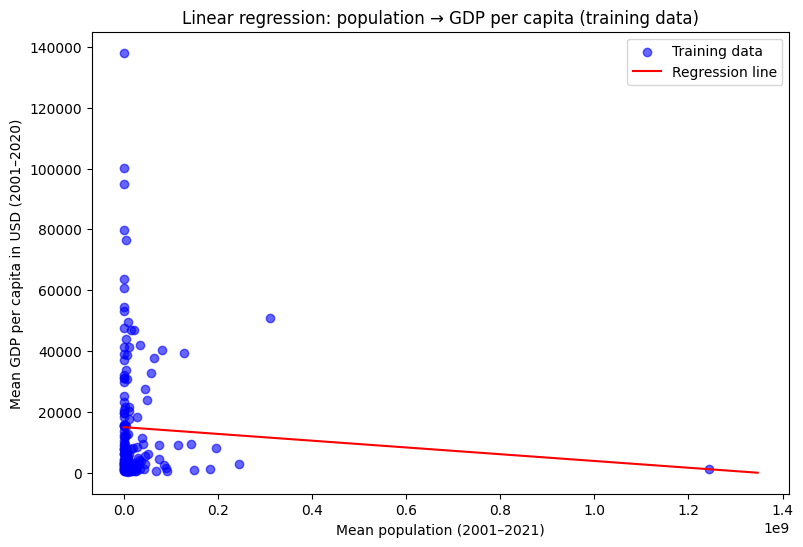

In [178]:
plt.figure(figsize=(9, 6))
plt.scatter(train["MeanPopulation"], train["MeanGDPperCapita"], color="blue", alpha=0.6, label="Training data")

line_x = np.linspace(0, df["MeanPopulation"].max(), 100).reshape(-1, 1)
plt.plot(line_x, regr.predict(line_x), color="red", label="Regression line")

plt.xlabel("Mean population (2001–2021)")
plt.ylabel("Mean GDP per capita in USD (2001–2020)")
plt.title("Linear regression: population → GDP per capita (training data)")
plt.legend()
plt.show()

**Result:** The regression line is almost flat compared to the spread of the data: it falls from about 15,000 USD at the left to about 0 at a population of 1.35 billion. Most training points are far from the line, especially the small countries with GDP per capita between 0 and about 138,000 USD. The training data contains only one country with a population above 1.2 billion, so this single point may have a strong influence on the slope of the line.

## Step 26: Model evaluation

In [179]:
test_x = np.asanyarray(test[["MeanPopulation"]])
test_y = np.asanyarray(test[["MeanGDPperCapita"]])
test_y_pred = regr.predict(test_x)

print("Mean absolute error (MAE):", round(np.mean(np.absolute(test_y_pred - test_y)), 2))
print("Mean squared error (MSE): ", round(np.mean((test_y_pred - test_y) ** 2), 2))
print("R² (test):                ", round(r2_score(test_y, test_y_pred), 4))
print("R² (training):            ", round(regr.score(train_x, train_y), 4))

Mean absolute error (MAE): 18233.74
Mean squared error (MSE):  803935347.42
R² (test):                 -0.016
R² (training):             0.003


**Result:** The model performs very poorly. On the test data, the mean absolute error is about 18,200 USD, larger than the model's intercept (14,934 USD). R² is 0.003 on the training data, so population explains only 0.3% of the variation in GDP per capita. On the test data R² is −0.016, so the model predicts slightly worse than simply using the average. A linear model with population as the only predictor is not suitable for explaining or predicting GDP per capita. This is consistent with the near-zero Pearson correlation in Task A.

## Conclusion

**Task A – Correlation:** The scatter plot shows no visible linear relationship between mean population and mean GDP per capita. Pearson r = −0.067 (p = 0.336, n = 208), so there is practically no linear correlation, and the result is not statistically significant. The richest countries per person are all very small (e.g. Monaco, Liechtenstein), while the largest countries differ strongly (United States about 50,800 USD, China about 5,300 USD, India about 1,300 USD).

**Task B – Regression:** The linear regression model (GDP per capita = 14,934 − 0.0000111 × population) explains only 0.3% of the variation in the training data (R² = 0.003) and performs slightly worse than the average on the test data (R² = −0.016). The mean absolute error is about 18,200 USD. For China, the model even predicts a negative GDP per capita. Population alone is not a suitable predictor of GDP per capita.

**Limitations:**
- The GDP data ends in 2020, so mean GDP per capita covers 2001–2020, while mean population covers 2001–2021.
- The 2021 population values are estimates (data last updated December 2021).
- 9 countries were excluded by the 10-year rule, including some of the poorest (Somalia, South Sudan, North Korea). Missing data is not random, so the final dataset slightly underrepresents very poor countries.
- Pearson correlation and linear regression only capture linear relationships and are sensitive to extreme values. The data contains strong outliers (China, India, very small rich states).
- The training data contains only one country with a population above 1.2 billion, so the regression line may depend strongly on which countries end up in the training set.

**Points for discussion:**
- Is the 10-year rule a reasonable way to handle missing values, or would another approach change the results?
- Which other factors could better explain GDP per capita?
- How do decisions during data cleaning affect which countries are represented, and what does that mean for conclusions drawn from the data?